In [4]:
!unzip dataset.zip -d /content/


Streaming output truncated to the last 5000 lines.
  inflating: /content/annotations/691_aro.npy  
  inflating: /content/annotations/691_exp.npy  
  inflating: /content/annotations/691_lnd.npy  
  inflating: /content/annotations/691_val.npy  
  inflating: /content/annotations/692_aro.npy  
  inflating: /content/annotations/692_exp.npy  
  inflating: /content/annotations/692_lnd.npy  
  inflating: /content/annotations/692_val.npy  
  inflating: /content/annotations/693_aro.npy  
  inflating: /content/annotations/693_exp.npy  
  inflating: /content/annotations/693_lnd.npy  
  inflating: /content/annotations/693_val.npy  
  inflating: /content/annotations/694_aro.npy  
  inflating: /content/annotations/694_exp.npy  
  inflating: /content/annotations/694_lnd.npy  
  inflating: /content/annotations/694_val.npy  
  inflating: /content/annotations/695_aro.npy  
  inflating: /content/annotations/695_exp.npy  
  inflating: /content/annotations/695_lnd.npy  
  inflating: /content/annotations/695

In [29]:
import zipfile
import os

zip_path = "/content/dataset.zip"      # path to zip file
extract_path = "/content"        # destination folder

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted to:", extract_path)
print("Files:", os.listdir(extract_path))


Extracted to: /content
Files: ['.config', 'samples', 'annotations', 'images', 'dataset.zip', 'sample_data']


In [30]:
import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, roc_auc_score
from scipy.stats import pearsonr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [31]:
# ======================================
# STEP 1: Custom Dataset
# ======================================
from PIL import Image

class AffectDataset(Dataset):
    def __init__(self, img_dir, filenames, expressions, valence, arousal, transform=None):
        self.img_dir = img_dir
        self.filenames = filenames
        self.expressions = expressions
        self.valence = valence
        self.arousal = arousal
        self.transform = transform

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.filenames[idx])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)

        expr = self.expressions[idx]
        val = self.valence[idx]
        aro = self.arousal[idx]

        return image, expr, val, aro


In [32]:
# ======================================
# STEP 2: Load Data (fixed for per-ID .npy files)
# ======================================
import glob

ANNOT_DIR = "/content/annotations"
IMG_DIR = "/content/images"   # adjust if your images folder name differs

# Collect all expression annotation files
exp_files = glob.glob(os.path.join(ANNOT_DIR, "*_exp.npy"))

filenames, expressions, valence, arousal = [], [], [], []

for exp_path in exp_files:
    base_id = os.path.basename(exp_path).split("_")[0]

    val_path = os.path.join(ANNOT_DIR, f"{base_id}_val.npy")
    aro_path = os.path.join(ANNOT_DIR, f"{base_id}_aro.npy")

    # Load labels
    exp = np.load(exp_path)
    val = np.load(val_path)
    aro = np.load(aro_path)

    # Convert scalars safely
    exp = int(exp.item()) if exp.ndim == 0 else int(exp[0])
    val = float(val.item()) if val.ndim == 0 else float(val[0])
    aro = float(aro.item()) if aro.ndim == 0 else float(aro[0])

    # Assume images are JPG (change to .png if needed)
    img_filename = f"{base_id}.jpg"
    img_path = os.path.join(IMG_DIR, img_filename)
    if os.path.exists(img_path):
        filenames.append(img_filename)
        expressions.append(exp)
        valence.append(val)
        arousal.append(aro)

print("Total samples loaded:", len(filenames))
print("First few:", list(zip(filenames[:5], expressions[:5], valence[:5], arousal[:5])))


Total samples loaded: 3999
First few: [('3039.jpg', 4, -0.0583355, 0.533662), ('3285.jpg', 3, 0.261905, 0.865079), ('918.jpg', 7, -0.493612, 0.512969), ('1380.jpg', 2, -0.928571, -0.214286), ('166.jpg', 5, -0.833333, 0.357143)]


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_expr_train, y_expr_temp, y_val_train, y_val_temp, y_aro_train, y_aro_temp = train_test_split(
    filenames, expressions, valence, arousal, test_size=0.3, random_state=42
)

X_val, X_test, y_expr_val, y_expr_test, y_val_val, y_val_test, y_aro_val, y_aro_test = train_test_split(
    X_temp, y_expr_temp, y_val_temp, y_aro_temp, test_size=0.5, random_state=42
)

print("Train size:", len(X_train), "Val size:", len(X_val), "Test size:", len(X_test))


Train size: 2799 Val size: 600 Test size: 600


In [34]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])


In [35]:
# Datasets
train_ds = AffectDataset(IMG_DIR, X_train, y_expr_train, y_val_train, y_aro_train, transform)
val_ds = AffectDataset(IMG_DIR, X_val, y_expr_val, y_val_val, y_aro_val, transform)
test_ds = AffectDataset(IMG_DIR, X_test, y_expr_test, y_val_test, y_aro_test, transform)

In [36]:
# Dataloaders
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

In [37]:
# ======================================
# STEP 3: Multi-Task CNN (ResNet50 example)
# ======================================
class MultiTaskModel(nn.Module):
    def __init__(self, base_model):
        super(MultiTaskModel, self).__init__()
        self.backbone = base_model
        self.backbone.fc = nn.Identity()  # remove last layer

        # Heads
        self.expr_head = nn.Linear(2048, 8)   # for 8 expressions
        self.val_head = nn.Linear(2048, 1)    # regression
        self.aro_head = nn.Linear(2048, 1)    # regression

    def forward(self, x):
        feats = self.backbone(x)
        expr = self.expr_head(feats)
        val = torch.tanh(self.val_head(feats))
        aro = torch.tanh(self.aro_head(feats))
        return expr, val, aro

# Load pretrained ResNet50
resnet = models.resnet50(pretrained=True)
model = MultiTaskModel(resnet).to(device)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [38]:
# ======================================
# STEP 4: Training Setup
# ======================================
criterion_expr = nn.CrossEntropyLoss()
criterion_reg = nn.MSELoss()

optimizer = optim.Adam(model.parameters(), lr=1e-4)

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    for imgs, expr, val, aro in loader:
        imgs, expr, val, aro = imgs.to(device), expr.to(device), val.float().to(device), aro.float().to(device)

        optimizer.zero_grad()
        out_expr, out_val, out_aro = model(imgs)

        loss_expr = criterion_expr(out_expr, expr)
        loss_val = criterion_reg(out_val.squeeze(), val)
        loss_aro = criterion_reg(out_aro.squeeze(), aro)

        loss = loss_expr + loss_val + loss_aro
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


In [39]:
# ======================================
# STEP 5: Validation Function
# ======================================
def evaluate(model, loader):
    model.eval()
    all_expr_true, all_expr_pred = [], []
    all_val_true, all_val_pred = [], []
    all_aro_true, all_aro_pred = [], []

    with torch.no_grad():
        for imgs, expr, val, aro in loader:
            imgs = imgs.to(device)
            out_expr, out_val, out_aro = model(imgs)

            preds_expr = out_expr.argmax(dim=1).cpu().numpy()
            all_expr_pred.extend(preds_expr)
            all_expr_true.extend(expr.numpy())

            all_val_pred.extend(out_val.cpu().squeeze().numpy())
            all_aro_pred.extend(out_aro.cpu().squeeze().numpy())
            all_val_true.extend(val.numpy())
            all_aro_true.extend(aro.numpy())

    acc = accuracy_score(all_expr_true, all_expr_pred)
    f1 = f1_score(all_expr_true, all_expr_pred, average="weighted")
    kappa = cohen_kappa_score(all_expr_true, all_expr_pred)
    corr_val, _ = pearsonr(all_val_true, all_val_pred)
    corr_aro, _ = pearsonr(all_aro_true, all_aro_pred)

    return acc, f1, kappa, corr_val, corr_aro


In [40]:
# ======================================
# STEP 6: Training Loop (with history tracking)
# ======================================
EPOCHS = 10

train_losses = []
val_accs = []
val_f1s = []
val_kappas = []
val_corr_val = []
val_corr_aro = []

for epoch in range(EPOCHS):
    # Training
    train_loss = train_one_epoch(model, train_loader, optimizer)
    train_losses.append(train_loss)

    # Validation
    acc, f1, kappa, corr_val, corr_aro = evaluate(model, val_loader)
    val_accs.append(acc)
    val_f1s.append(f1)
    val_kappas.append(kappa)
    val_corr_val.append(corr_val)
    val_corr_aro.append(corr_aro)

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Loss: {train_loss:.4f} | Acc: {acc:.4f} | F1: {f1:.4f} | "
          f"Kappa: {kappa:.4f} | Corr(V): {corr_val:.4f} | Corr(A): {corr_aro:.4f}")


Epoch 1/10 | Loss: 2.0938 | Acc: 0.3817 | F1: 0.3714 | Kappa: 0.2941 | Corr(V): 0.5014 | Corr(A): 0.4337
Epoch 2/10 | Loss: 1.2793 | Acc: 0.3900 | F1: 0.3796 | Kappa: 0.3013 | Corr(V): 0.4859 | Corr(A): 0.3600
Epoch 3/10 | Loss: 0.5138 | Acc: 0.4050 | F1: 0.3988 | Kappa: 0.3173 | Corr(V): 0.5220 | Corr(A): 0.3897
Epoch 4/10 | Loss: 0.1865 | Acc: 0.4017 | F1: 0.3989 | Kappa: 0.3132 | Corr(V): 0.4517 | Corr(A): 0.3912
Epoch 5/10 | Loss: 0.1040 | Acc: 0.4083 | F1: 0.4097 | Kappa: 0.3229 | Corr(V): 0.5335 | Corr(A): 0.4196
Epoch 6/10 | Loss: 0.0922 | Acc: 0.4050 | F1: 0.4006 | Kappa: 0.3190 | Corr(V): 0.5248 | Corr(A): 0.4018
Epoch 7/10 | Loss: 0.0779 | Acc: 0.4017 | F1: 0.3982 | Kappa: 0.3143 | Corr(V): 0.4791 | Corr(A): 0.4304
Epoch 8/10 | Loss: 0.0638 | Acc: 0.3833 | F1: 0.3807 | Kappa: 0.2939 | Corr(V): 0.4824 | Corr(A): 0.4102
Epoch 9/10 | Loss: 0.1134 | Acc: 0.3783 | F1: 0.3784 | Kappa: 0.2914 | Corr(V): 0.4300 | Corr(A): 0.4046
Epoch 10/10 | Loss: 0.3040 | Acc: 0.3450 | F1: 0.3454 |

In [41]:
import torch.nn as nn

# Classification loss (multi-class cross entropy)
criterion_cls = nn.CrossEntropyLoss()

# Regression loss (Mean Squared Error)
criterion_reg = nn.MSELoss()

def evaluate_with_loss(model, loader, criterion_cls, criterion_reg):
    model.eval()
    total_loss = 0.0
    all_expr_true, all_expr_pred = [], []
    all_val_true, all_val_pred = [], []
    all_aro_true, all_aro_pred = [], []

    with torch.no_grad():
        for imgs, expr, val, aro in loader:
            imgs, expr, val, aro = imgs.to(device), expr.to(device), val.to(device), aro.to(device)
            out_expr, out_val, out_aro = model(imgs)

            # Compute losses
            loss_cls = criterion_cls(out_expr, expr)
            loss_val = criterion_reg(out_val.squeeze(), val)
            loss_aro = criterion_reg(out_aro.squeeze(), aro)
            loss = loss_cls + loss_val + loss_aro
            total_loss += loss.item()

            # Predictions
            preds_expr = out_expr.argmax(dim=1).cpu().numpy()
            all_expr_pred.extend(preds_expr)
            all_expr_true.extend(expr.cpu().numpy())
            all_val_pred.extend(out_val.cpu().squeeze().numpy())
            all_aro_pred.extend(out_aro.cpu().squeeze().numpy())
            all_val_true.extend(val.cpu().numpy())
            all_aro_true.extend(aro.cpu().numpy())

    avg_loss = total_loss / len(loader)

    # Classification metrics
    acc = accuracy_score(all_expr_true, all_expr_pred)
    f1 = f1_score(all_expr_true, all_expr_pred, average="weighted")
    kappa = cohen_kappa_score(all_expr_true, all_expr_pred)

    # Correlations
    corr_val, _ = pearsonr(all_val_true, all_val_pred)
    corr_aro, _ = pearsonr(all_aro_true, all_aro_pred)

    return avg_loss, acc, f1, kappa, corr_val, corr_aro


In [42]:
val_losses = []

for epoch in range(EPOCHS):
   val_loss, acc, f1, kappa, corr_val, corr_aro = evaluate_with_loss(model, val_loader, criterion_cls, criterion_reg)
   val_losses.append(val_loss)

In [43]:
from sklearn.metrics import mean_squared_error
import numpy as np

def evaluate_with_regression(model, loader):
    model.eval()
    all_expr_true, all_expr_pred = [], []
    all_val_true, all_val_pred = [], []
    all_aro_true, all_aro_pred = [], []

    with torch.no_grad():
        for imgs, expr, val, aro in loader:
            imgs = imgs.to(device)
            out_expr, out_val, out_aro = model(imgs)

            preds_expr = out_expr.argmax(dim=1).cpu().numpy()
            all_expr_pred.extend(preds_expr)
            all_expr_true.extend(expr.numpy())

            all_val_pred.extend(out_val.cpu().squeeze().numpy())
            all_aro_pred.extend(out_aro.cpu().squeeze().numpy())
            all_val_true.extend(val.numpy())
            all_aro_true.extend(aro.numpy())

    # Classification
    acc = accuracy_score(all_expr_true, all_expr_pred)
    f1 = f1_score(all_expr_true, all_expr_pred, average="weighted")
    kappa = cohen_kappa_score(all_expr_true, all_expr_pred)

    # Regression (manual RMSE)
    mse_val = mean_squared_error(all_val_true, all_val_pred)
    rmse_val = np.sqrt(mse_val)

    mse_aro = mean_squared_error(all_aro_true, all_aro_pred)
    rmse_aro = np.sqrt(mse_aro)

    corr_val, _ = pearsonr(all_val_true, all_val_pred)
    corr_aro, _ = pearsonr(all_aro_true, all_aro_pred)

    return acc, f1, kappa, rmse_val, corr_val, rmse_aro, corr_aro


# Final evaluation on test set
acc, f1, kappa, rmse_val, corr_val, rmse_aro, corr_aro = evaluate_with_regression(model, test_loader)

print("=== Final Test Results ===")
print(f"Accuracy: {acc:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Cohen’s Kappa: {kappa:.4f}")
print(f"Valence RMSE: {rmse_val:.4f} | Correlation: {corr_val:.4f}")
print(f"Arousal RMSE: {rmse_aro:.4f} | Correlation: {corr_aro:.4f}")


=== Final Test Results ===
Accuracy: 0.3983
F1 Score: 0.3972
Cohen’s Kappa: 0.3129
Valence RMSE: 0.4177 | Correlation: 0.5726
Arousal RMSE: 0.3804 | Correlation: 0.3934


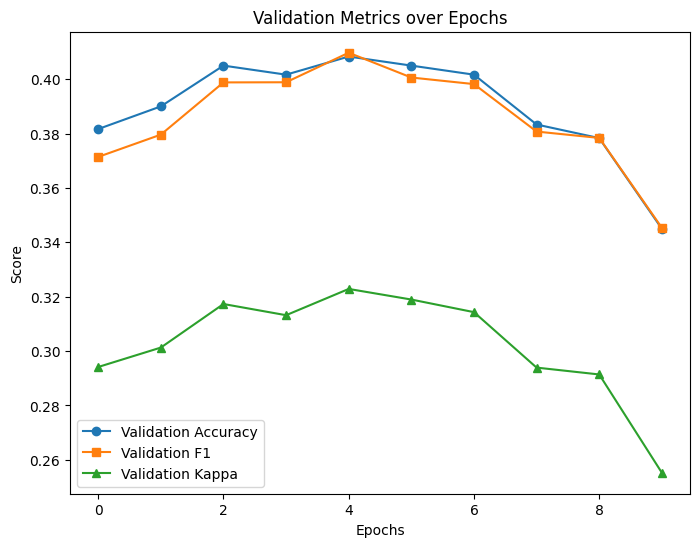

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.plot(val_accs, label="Validation Accuracy", marker="o")
plt.plot(val_f1s, label="Validation F1", marker="s")
plt.plot(val_kappas, label="Validation Kappa", marker="^")
plt.xlabel("Epochs")
plt.ylabel("Score")
plt.title("Validation Metrics over Epochs")
plt.legend()
plt.show()



# EfficientNet-B0

In [45]:
from torchvision.models import efficientnet_b0

class MultiTaskEfficientNet(nn.Module):
    def __init__(self, base_model):
        super(MultiTaskEfficientNet, self).__init__()
        self.backbone = base_model
        self.backbone.classifier = nn.Identity()  # remove last FC layer
        in_features = 1280  # output of EfficientNet-B0

        # Heads
        self.expr_head = nn.Linear(in_features, 8)   # expressions
        self.val_head = nn.Linear(in_features, 1)    # regression
        self.aro_head = nn.Linear(in_features, 1)    # regression

    def forward(self, x):
        feats = self.backbone(x)
        expr = self.expr_head(feats)
        val = torch.tanh(self.val_head(feats))
        aro = torch.tanh(self.aro_head(feats))
        return expr, val, aro

# Load pretrained EfficientNet
effnet = efficientnet_b0(pretrained=True)
model2 = MultiTaskEfficientNet(effnet).to(device)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [46]:
# Training
criterion_expr = nn.CrossEntropyLoss()
criterion_reg = nn.MSELoss()
optimizer2 = optim.Adam(model2.parameters(), lr=1e-4)

In [47]:
# Training + Validation Loop
EPOCHS = 10

train_losses2 = []
val_accs2 = []
val_f1s2 = []
val_kappas2 = []
val_corr_val2 = []
val_corr_aro2 = []

for epoch in range(EPOCHS):
    # Training
    train_loss = train_one_epoch(model2, train_loader, optimizer2)
    train_losses2.append(train_loss)

    # Validation
    acc, f1, kappa, corr_val, corr_aro = evaluate(model2, val_loader)
    val_accs2.append(acc)
    val_f1s2.append(f1)
    val_kappas2.append(kappa)
    val_corr_val2.append(corr_val)
    val_corr_aro2.append(corr_aro)

    print(f"[EfficientNet] Epoch {epoch+1}/{EPOCHS} | "
          f"Loss: {train_loss:.4f} | Acc: {acc:.4f} | F1: {f1:.4f} | "
          f"Kappa: {kappa:.4f} | Corr(V): {corr_val:.4f} | Corr(A): {corr_aro:.4f}")


[EfficientNet] Epoch 1/10 | Loss: 2.3904 | Acc: 0.2450 | F1: 0.2143 | Kappa: 0.1399 | Corr(V): 0.3186 | Corr(A): 0.2299
[EfficientNet] Epoch 2/10 | Loss: 1.9784 | Acc: 0.3100 | F1: 0.3018 | Kappa: 0.2120 | Corr(V): 0.4086 | Corr(A): 0.2705
[EfficientNet] Epoch 3/10 | Loss: 1.6528 | Acc: 0.3500 | F1: 0.3507 | Kappa: 0.2566 | Corr(V): 0.4071 | Corr(A): 0.2785
[EfficientNet] Epoch 4/10 | Loss: 1.3547 | Acc: 0.3767 | F1: 0.3748 | Kappa: 0.2857 | Corr(V): 0.4138 | Corr(A): 0.3042
[EfficientNet] Epoch 5/10 | Loss: 1.0543 | Acc: 0.3967 | F1: 0.3953 | Kappa: 0.3089 | Corr(V): 0.4492 | Corr(A): 0.3142
[EfficientNet] Epoch 6/10 | Loss: 0.7839 | Acc: 0.4033 | F1: 0.3990 | Kappa: 0.3163 | Corr(V): 0.4438 | Corr(A): 0.2943
[EfficientNet] Epoch 7/10 | Loss: 0.5654 | Acc: 0.4083 | F1: 0.4067 | Kappa: 0.3223 | Corr(V): 0.4380 | Corr(A): 0.3085
[EfficientNet] Epoch 8/10 | Loss: 0.4127 | Acc: 0.3883 | F1: 0.3851 | Kappa: 0.2987 | Corr(V): 0.4437 | Corr(A): 0.3077
[EfficientNet] Epoch 9/10 | Loss: 0.2991

In [48]:
acc, f1, kappa, rmse_val, corr_val, rmse_aro, corr_aro = evaluate_with_regression(model2, test_loader)

print("=== Final Test Results (EfficientNet) ===")
print(f"Accuracy: {acc:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Cohen’s Kappa: {kappa:.4f}")
print(f"Valence RMSE: {rmse_val:.4f} | Correlation: {corr_val:.4f}")
print(f"Arousal RMSE: {rmse_aro:.4f} | Correlation: {corr_aro:.4f}")

=== Final Test Results (EfficientNet) ===
Accuracy: 0.4350
F1 Score: 0.4336
Cohen’s Kappa: 0.3546
Valence RMSE: 0.3960 | Correlation: 0.5546
Arousal RMSE: 0.3706 | Correlation: 0.3678


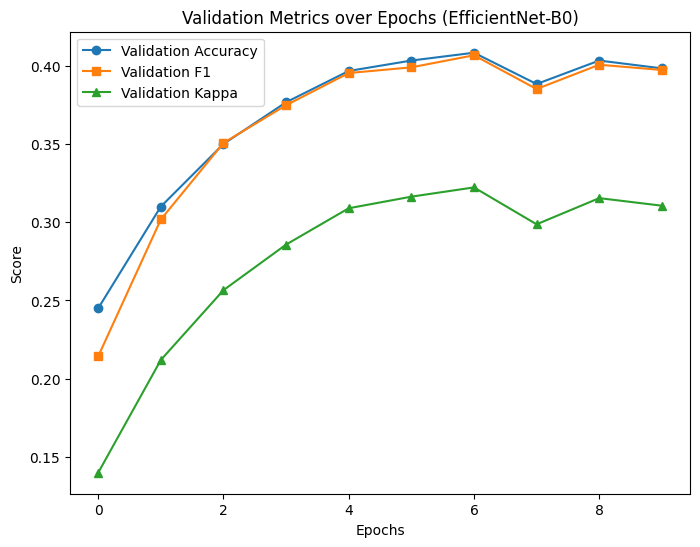

In [49]:
plt.figure(figsize=(8,6))
plt.plot(val_accs2, label="Validation Accuracy", marker="o")
plt.plot(val_f1s2, label="Validation F1", marker="s")
plt.plot(val_kappas2, label="Validation Kappa", marker="^")
plt.xlabel("Epochs")
plt.ylabel("Score")
plt.title("Validation Metrics over Epochs (EfficientNet-B0)")
plt.legend()
plt.show()

In [50]:
label_names = {
    0: "Angry",
    1: "Disgust",
    2: "Fear",
    3: "Happy",
    4: "Sad",
    5: "Surprise",
    6: "Neutral",
    7: "Contempt"
}


In [51]:
import matplotlib.pyplot as plt

def save_sample_predictions(model, loader, num_samples=4, folder="samples"):
    import os
    os.makedirs(folder, exist_ok=True)
    model.eval()
    saved = 0

    with torch.no_grad():
        for imgs, expr, val, aro in loader:
            imgs, expr = imgs.to(device), expr.to(device)
            out_expr, _, _ = model(imgs)
            preds = out_expr.argmax(dim=1)

            for i in range(len(expr)):
                true_label = expr[i].item()
                pred_label = preds[i].item()
                img = imgs[i].cpu().permute(1,2,0).numpy()
                img = (img - img.min()) / (img.max() - img.min())  # normalize for display

                plt.imshow(img)
                plt.axis("off")
                plt.title(f"GT: {label_names[true_label]}, Pred: {label_names[pred_label]}")
                if true_label == pred_label:
                    fname = f"{folder}/correct_{saved}.png"
                else:
                    fname = f"{folder}/wrong_{saved}.png"
                plt.savefig(fname)
                plt.close()

                saved += 1
                if saved >= num_samples:
                    return


In [52]:
save_sample_predictions(model, test_loader, num_samples=6, folder="samples")
